# Heart Disease Prediction – Logistic Regression

**Goal:** Binary classification: predict **presence / absence of heart disease** from clinical measurements.

**Dataset:** `Heart_Disease_Prediction.csv` – 270 patients, 13 features

**Approach:** EDA → IQR outlier check → feature distributions → scaling → Logistic Regression → accuracy, classification report and confusion matrix.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Load the data

In [2]:
df=pd.read_csv('../data/Heart_Disease_Prediction.csv')

In [3]:
df

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,52,1,3,172,199,1,0,162,0,0.5,1,0,7,Absence
266,44,1,2,120,263,0,0,173,0,0.0,1,0,7,Absence
267,56,0,2,140,294,0,2,153,0,1.3,2,0,3,Absence
268,57,1,4,140,192,0,0,148,0,0.4,2,0,6,Absence


## Exploratory data analysis

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      270 non-null    int64  
 1   Sex                      270 non-null    int64  
 2   Chest pain type          270 non-null    int64  
 3   BP                       270 non-null    int64  
 4   Cholesterol              270 non-null    int64  
 5   FBS over 120             270 non-null    int64  
 6   EKG results              270 non-null    int64  
 7   Max HR                   270 non-null    int64  
 8   Exercise angina          270 non-null    int64  
 9   ST depression            270 non-null    float64
 10  Slope of ST              270 non-null    int64  
 11  Number of vessels fluro  270 non-null    int64  
 12  Thallium                 270 non-null    int64  
 13  Heart Disease            270 non-null    object 
dtypes: float64(1), int64(12), 

In [5]:
df.shape

(270, 14)

In [6]:
df.isnull().sum()

Age                        0
Sex                        0
Chest pain type            0
BP                         0
Cholesterol                0
FBS over 120               0
EKG results                0
Max HR                     0
Exercise angina            0
ST depression              0
Slope of ST                0
Number of vessels fluro    0
Thallium                   0
Heart Disease              0
dtype: int64

In [7]:
X = df.drop('Heart Disease', axis=1)   
y = df['Heart Disease']           
X

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,52,1,3,172,199,1,0,162,0,0.5,1,0,7
266,44,1,2,120,263,0,0,173,0,0.0,1,0,7
267,56,0,2,140,294,0,2,153,0,1.3,2,0,3
268,57,1,4,140,192,0,0,148,0,0.4,2,0,6


## Outlier detection (IQR)

In [8]:
for col in X:
    Q1 = np.percentile(df[col], 25)
    Q3 = np.percentile(df[col], 75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers_count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {outliers_count} outliers (range: {lower:.2f} to {upper:.2f})")

Age: 0 outliers (range: 28.50 to 80.50)
Sex: 0 outliers (range: -1.50 to 2.50)
Chest pain type: 20 outliers (range: 1.50 to 5.50)
BP: 9 outliers (range: 90.00 to 170.00)
Cholesterol: 5 outliers (range: 112.50 to 380.50)
FBS over 120: 40 outliers (range: 0.00 to 0.00)
EKG results: 0 outliers (range: -3.00 to 5.00)
Max HR: 1 outliers (range: 83.50 to 215.50)
Exercise angina: 0 outliers (range: -1.50 to 2.50)
ST depression: 4 outliers (range: -2.40 to 4.00)
Slope of ST: 0 outliers (range: -0.50 to 3.50)
Number of vessels fluro: 19 outliers (range: -1.50 to 2.50)
Thallium: 0 outliers (range: -3.00 to 13.00)


## Feature distributions

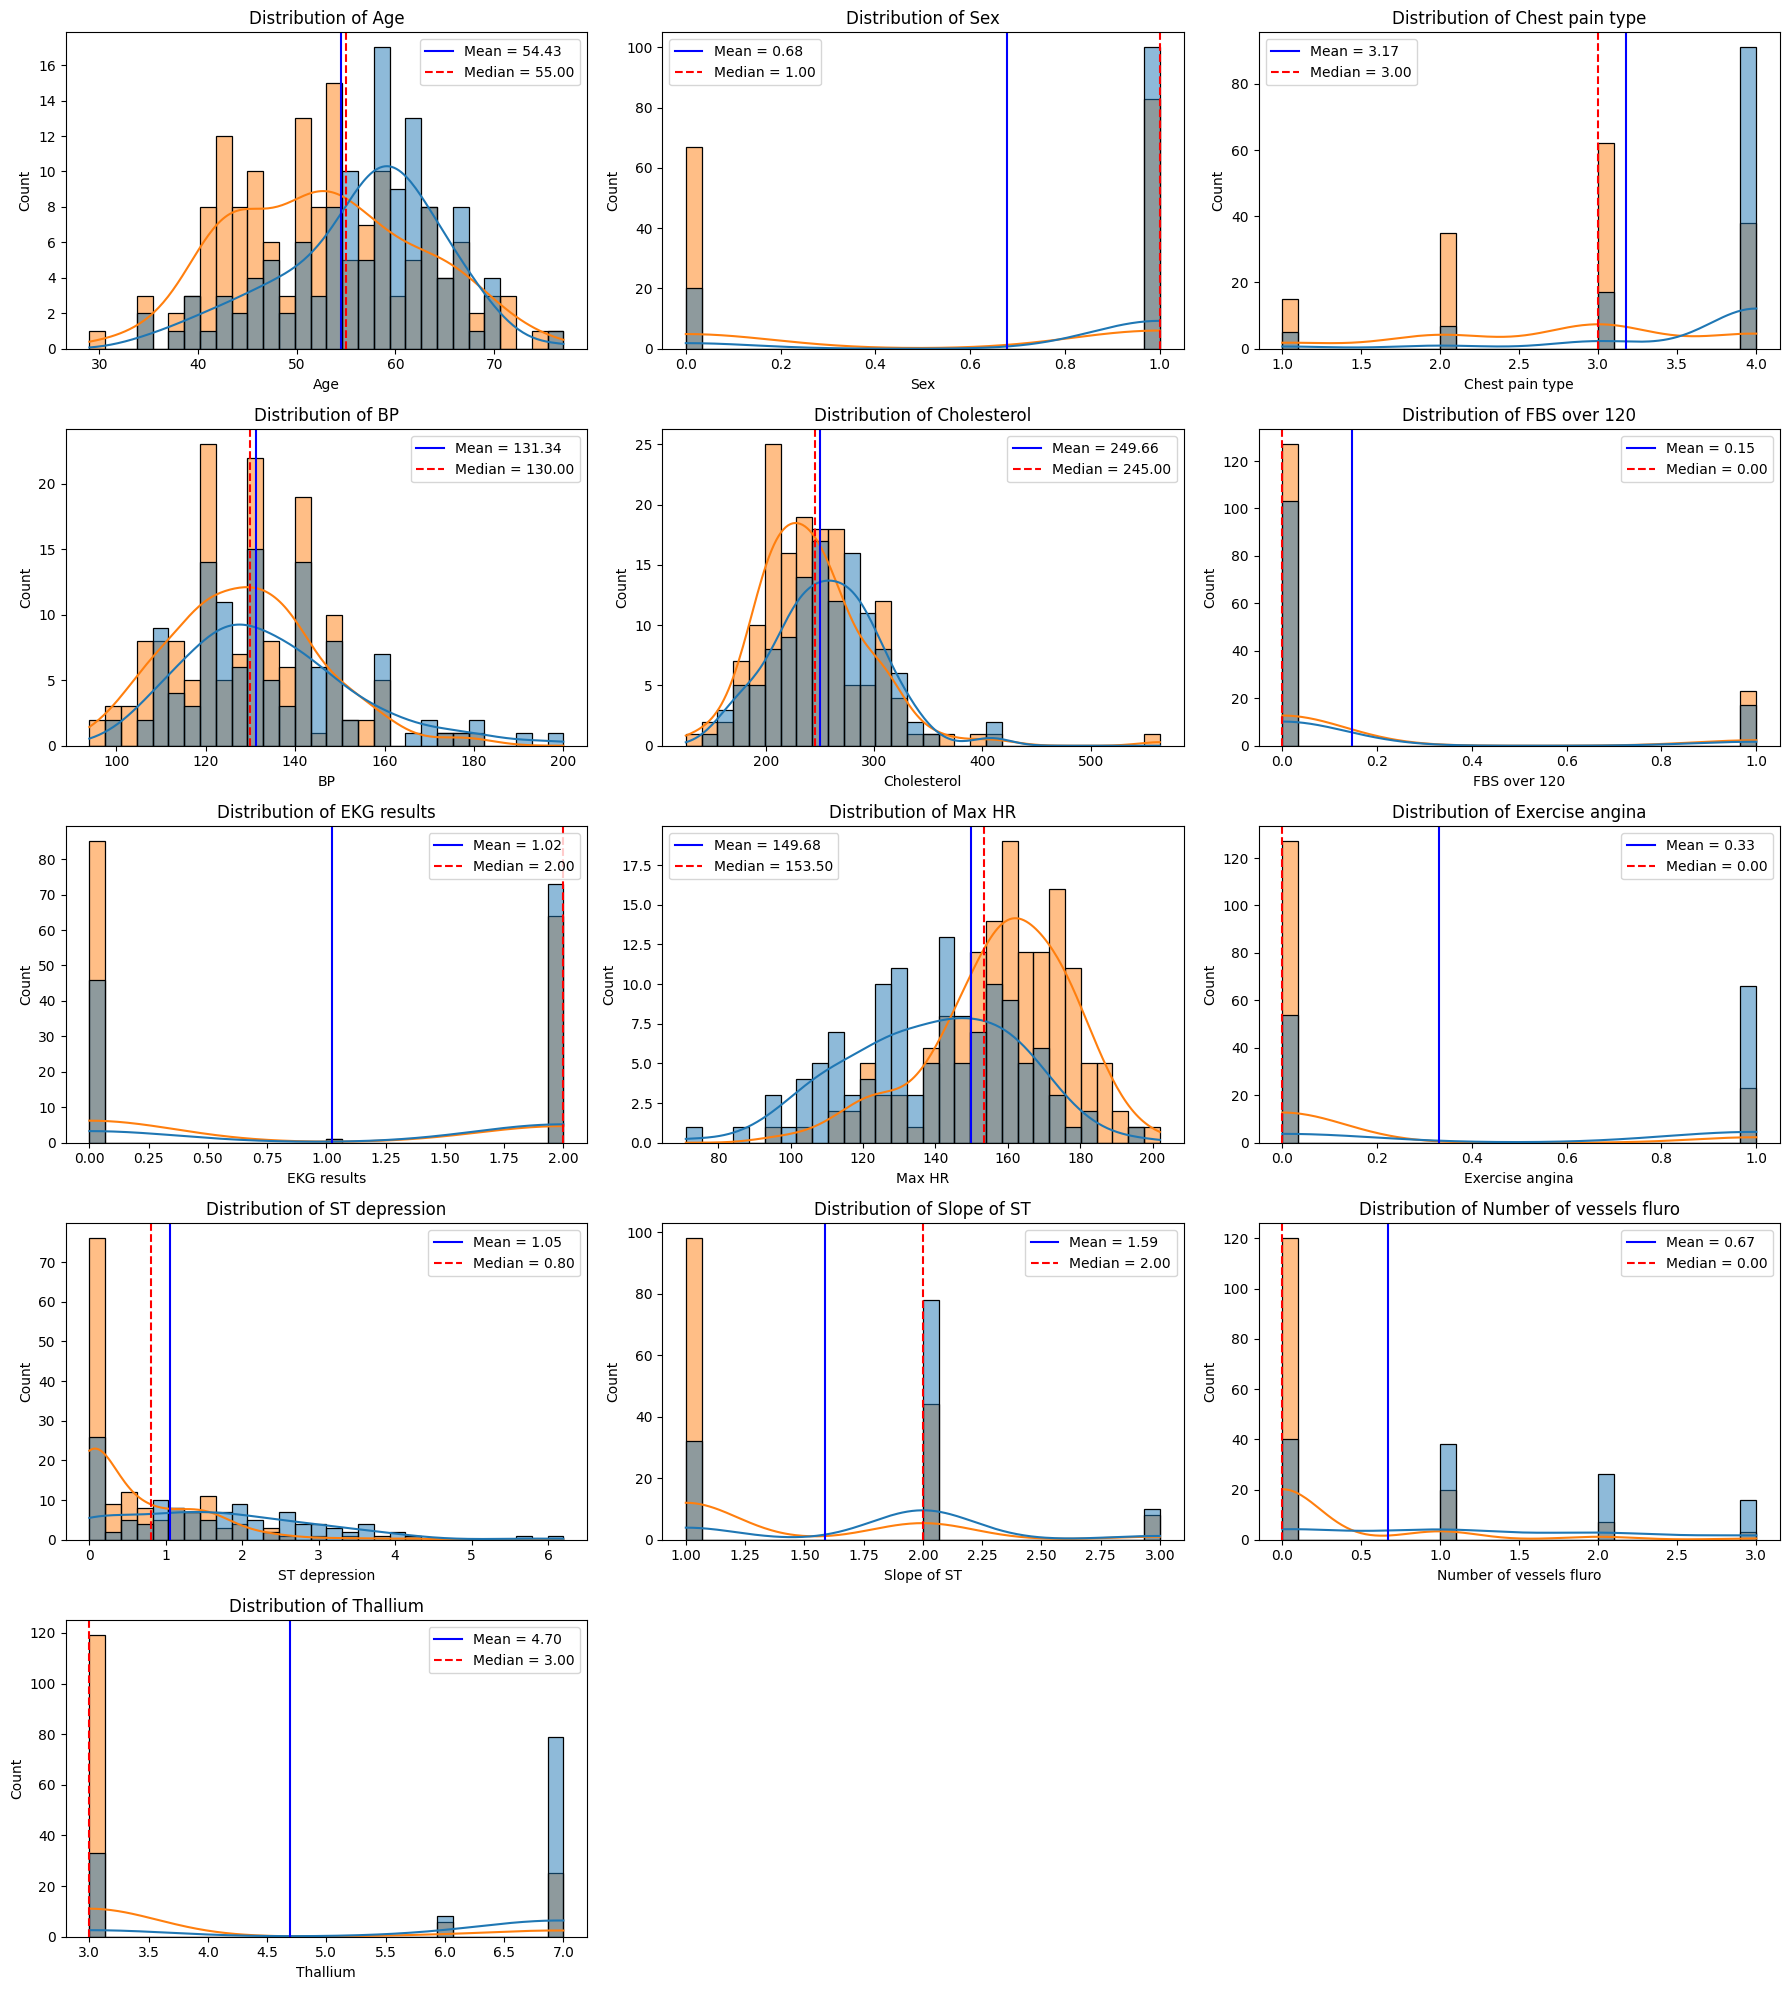

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset
df = pd.read_csv("../data/Heart_Disease_Prediction.csv")



features = df.columns[:-1]  

n_cols = 3
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(features):

    sns.histplot(
        data=df,
        x=col,
        hue="Heart Disease",
        kde=True,
        bins=30,
        ax=axes[i]
    )

    mean_val = df[col].mean()
    median_val = df[col].median()

    axes[i].axvline(
        mean_val,
        color="blue",
        linestyle="-",
        label=f"Mean = {mean_val:.2f}"
    )

    axes[i].axvline(
        median_val,
        color="red",
        linestyle="--",
        label=f"Median = {median_val:.2f}"
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].legend()


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()




## Feature scaling

In [10]:
from sklearn.preprocessing import StandardScaler, RobustScaler


std_scaler = StandardScaler()
robust_scaler = RobustScaler()

# Standard Scaling
df[['Age', 'BP', 'Cholesterol']] = std_scaler.fit_transform(
    df[['Age', 'BP', 'Cholesterol']]
)

# Robust Scaling
df[['Max HR', 'ST depression']] = robust_scaler.fit_transform(
    df[['Max HR', 'ST depression']]
)


df.head()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,1.712094,1,4,-0.075410,1.402212,0,2,-1.348485,0,1.0000,2,3,3,Presence
1,1.382140,0,3,-0.916759,6.093004,0,2,0.196970,0,0.5000,2,0,7,Absence
2,0.282294,1,2,-0.411950,0.219823,0,0,-0.378788,0,-0.3125,1,0,7,Presence
3,1.052186,1,4,-0.187590,0.258589,0,0,-1.469697,1,-0.3750,2,1,7,Absence
4,2.152032,0,2,-0.636310,0.374890,0,2,-0.984848,1,-0.3750,1,1,3,Absence


## Train / test split

In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Model training & evaluation

Train Accuracy : 0.8519
Test  Accuracy : 0.8519

Classification Report:

              precision    recall  f1-score   support

     Absence       0.92      0.80      0.86        30
    Presence       0.79      0.92      0.85        24

    accuracy                           0.85        54
   macro avg       0.85      0.86      0.85        54
weighted avg       0.86      0.85      0.85        54



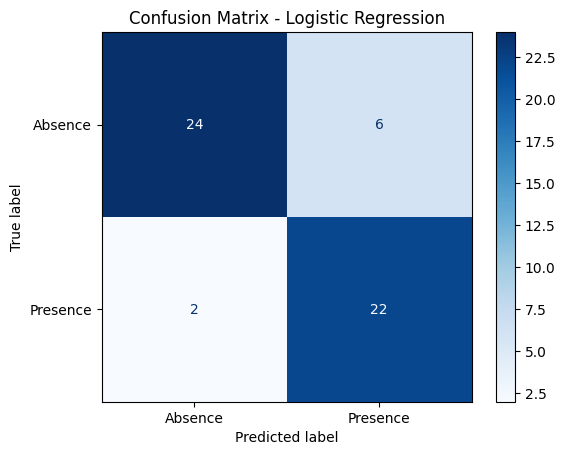

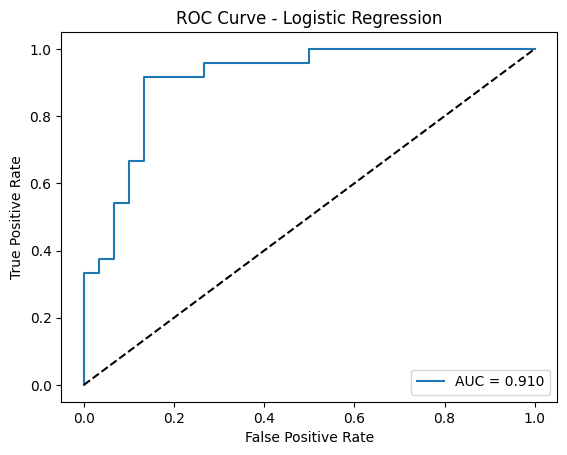

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt


log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)


y_pred = log_reg.predict(X_test)


acc_train = log_reg.score(X_train, y_train)
acc_test  = accuracy_score(y_test, y_pred)

print(f"Train Accuracy : {acc_train:.4f}")
print(f"Test  Accuracy : {acc_test:.4f}\n")

print("Classification Report:\n")
print(classification_report(y_test, y_pred))


cm = confusion_matrix(y_test, y_pred, labels=log_reg.classes_)
ConfusionMatrixDisplay(cm, display_labels=log_reg.classes_).plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()


pos_label = "Presence"
y_proba = log_reg.predict_proba(X_test)[:, list(log_reg.classes_).index(pos_label)]
auc = roc_auc_score((y_test == pos_label).astype(int), y_proba)
fpr, tpr, _ = roc_curve((y_test == pos_label).astype(int), y_proba)

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()


In [13]:
from sklearn.linear_model import LogisticRegression
reg=LogisticRegression(max_iter=1000)
reg.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [14]:
y_pred=reg.predict(X_test)

In [15]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     Absence       0.92      0.80      0.86        30
    Presence       0.79      0.92      0.85        24

    accuracy                           0.85        54
   macro avg       0.85      0.86      0.85        54
weighted avg       0.86      0.85      0.85        54



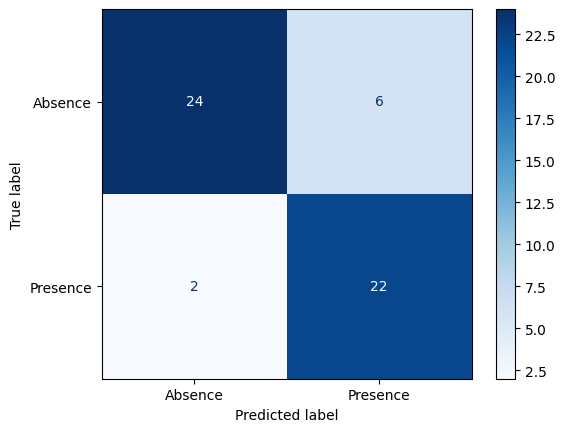

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=reg.classes_
).plot(cmap="Blues")

## Results & conclusion

| Metric | Value |
|---|---|
| Test accuracy | **0.85** |
| Recall (Presence) | 0.92 |
| Precision (Presence) | 0.79 |

* High recall on the *Presence* class matters most here: missing a sick patient is worse than a false alarm.
* Train and test accuracy are equal (0.85), so the model is not overfitting.